# Planning a Radar Tracking Mission for a Research UAV: Filter Development across Coordinate Systems

## Part I. Mission Build: Designing the Tracking Filter
### 1. Trajectory generation in the Cartesian coordinate system

In [1]:
import numpy as np
from matplotlib import pyplot as plt

In [2]:
# defining the constants
POINTS = 26
M_RUNS = 500
T = 2

VX_INIT = -50
VY_INIT = -45

# far-range approach and close fly-by
X_INIT_FAR = 13500 / np.sqrt(2)
Y_INIT_FAR = 13500 / np.sqrt(2)
X_INIT_CLOSE = 3500 / np.sqrt(2)
Y_INIT_CLOSE = 3500 / np.sqrt(2)

# standard deviations of the measurement noise: the main case and the case for item 10 of Part II
SIGMA_D = 20
SIGMA_BETA = 0.02
SIGMA_D_PRECISE_BETA = 50
SIGMA_BETA_PRECISE_BETA = 0.0015

# the first steps are not shown on the error plots: the errors there are determined by X_{0,0}
START = 3

# fixed seed, so that the plots and the numbers in the report do not change after re-running
np.random.seed(7)

steps = np.arange(POINTS * T, step = T)

Uniform motion without random disturbances:
$$x_i = x_{i-1} + V^x_{i-1}T, \quad V^x_i = V^x_{i-1}, \qquad y_i = y_{i-1} + V^y_{i-1}T, \quad V^y_i = V^y_{i-1}$$

In [3]:
# a function to generate a deterministic true trajectory of the UAV moving uniformly
def generate_true_trajectory(init_x, init_y, size=POINTS, init_vx=VX_INIT, init_vy=VY_INIT, t=T):
    x = np.zeros(size)
    vx = np.zeros(size)
    y = np.zeros(size)
    vy = np.zeros(size)
    x[0], vx[0], y[0], vy[0] = init_x, init_vx, init_y, init_vy

    for i in range(1, size):
        x[i] = x[i-1] + vx[i-1] * t
        vx[i] = vx[i-1]
        y[i] = y[i-1] + vy[i-1] * t
        vy[i] = vy[i-1]

    return x, vx, y, vy

### 2. Generation of true range $D$ and azimuth $\beta$
$$D_i = \sqrt{x_i^2 + y_i^2}, \qquad \beta_i = \mathrm{arctg}\left(\frac{x_i}{y_i}\right)$$
The azimuth is counted from the $y$ axis clockwise. `np.arctan2(x, y)` is used: for $y > 0$ it equals $\mathrm{arctg}(x/y)$, and it does not fail at $y = 0$.

In [4]:
# a function to convert Cartesian coordinates to range and azimuth
def to_polar(x, y):
    return np.sqrt(x**2 + y**2), np.arctan2(x, y)

x_far, vx_far, y_far, vy_far = generate_true_trajectory(X_INIT_FAR, Y_INIT_FAR)
d_far, beta_far = to_polar(x_far, y_far)

print(f"D: {d_far[0]:.1f} -> {d_far[-1]:.1f} m, beta: {np.degrees(beta_far[0]):.2f} -> {np.degrees(beta_far[-1]):.2f} deg")

D: 13500.0 -> 10142.8 m, beta: 45.00 -> 44.00 deg


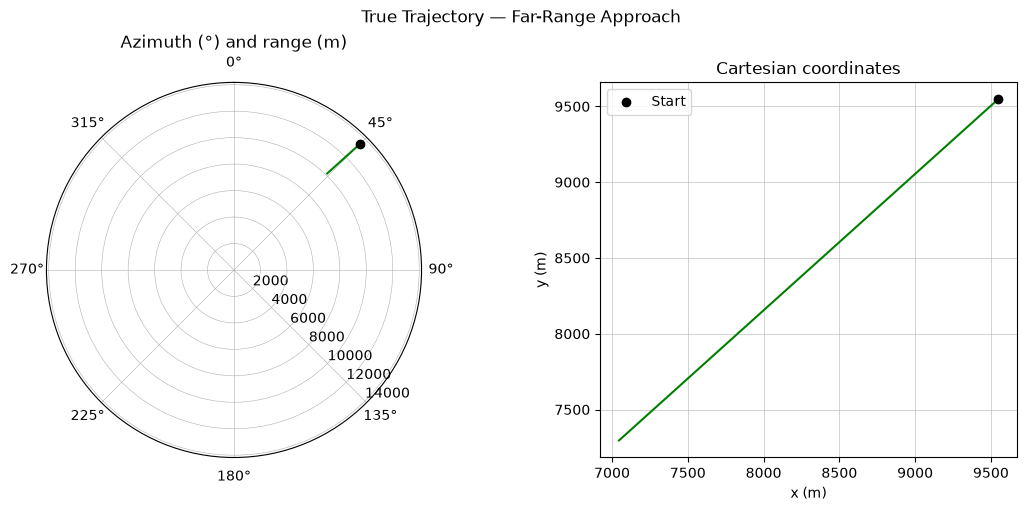

In [ ]:
def plot_true_trajectory(x, y, d, beta, title):
    fig = plt.figure(figsize=(11, 5), layout="constrained")
    ax_polar = fig.add_subplot(1, 2, 1, projection="polar")
    ax_cartesian = fig.add_subplot(1, 2, 2)

    ax_polar.set_theta_zero_location("N")
    ax_polar.set_theta_direction(-1)
    ax_polar.set_rlim(0, 1.05 * d.max())
    ax_polar.set_rlabel_position(135)
    ax_polar.set_title("Azimuth (°) and range (m)")

    ax_cartesian.set_title("Cartesian coordinates")
    ax_cartesian.set_xlabel("x (m)")
    ax_cartesian.set_ylabel("y (m)")
    ax_cartesian.set_aspect("equal", adjustable="box")

    for ax, horizontal, vertical in [(ax_polar, beta, d), (ax_cartesian, x, y)]:
        ax.plot(horizontal, vertical, color="green", linewidth=1.5)
        ax.scatter(horizontal[0], vertical[0], color="black", marker="o", zorder=3, label="Start")
        ax.grid(True, linewidth=0.4)

    ax_cartesian.legend(loc="upper left")
    fig.suptitle(title)
    plt.show()


plot_true_trajectory(x_far, y_far, d_far, beta_far, "True Trajectory — Far-Range Approach")

### 3. Measurement generation
$$D^m_i = D_i + \eta^D_i, \qquad \beta^m_i = \beta_i + \eta^\beta_i, \qquad \sigma_D = 20 \text{ m}, \quad \sigma_\beta = 0.02 \text{ rad}$$

In [5]:
# a function to generate the polar measurements of range and azimuth
def generate_measurements(d, beta, sigma_d, sigma_beta):
    d_m = d + np.random.normal(loc=0.0, scale=sigma_d, size=d.size)
    beta_m = beta + np.random.normal(loc=0.0, scale=sigma_beta, size=beta.size)
    return d_m, beta_m

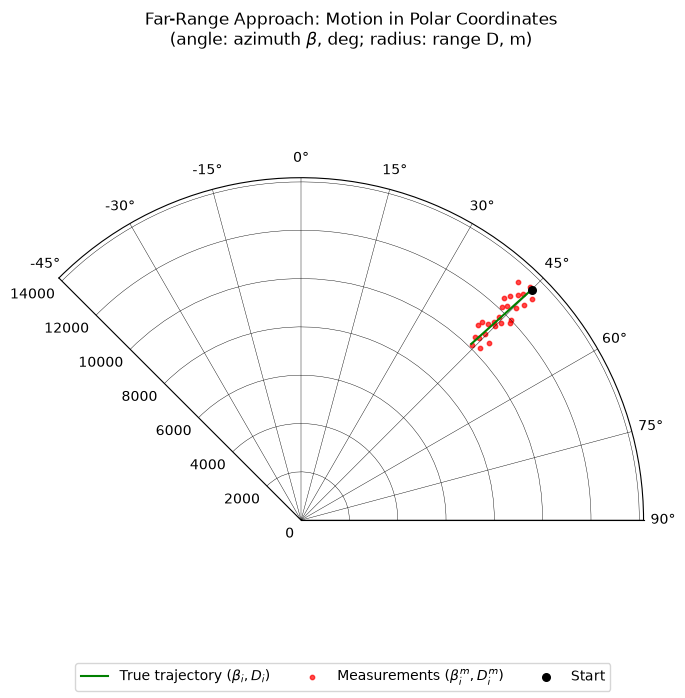

In [6]:
# a function to plot the true motion and the measurements in the polar coordinate system
def plot_polar(d, beta, d_m, beta_m, title):
    fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={"projection": "polar"})
    # azimuth is counted from the y axis (north) clockwise
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    ax.plot(beta, d, color="green", linewidth=1.5, label="True trajectory $(\\beta_i, D_i)$")
    ax.scatter(beta_m, d_m, color="red", s=10, alpha=0.7, label="Measurements $(\\beta^m_i, D^m_i)$")
    ax.scatter([beta[0]], [d[0]], color="black", marker="o", s=30, zorder=3, label="Start")
    ax.set_thetamin(-45)
    ax.set_thetamax(90)
    ax.set_rlim(0, 1.05 * np.max(d))
    ax.set_title(f"{title}\n(angle: azimuth $\\beta$, deg; radius: range D, m)")
    ax.grid(True, color="black", linewidth=0.3)
    fig.legend(frameon=True, loc="lower center", ncol=3)
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    plt.show()

d_m_far, beta_m_far = generate_measurements(d_far, beta_far, SIGMA_D, SIGMA_BETA)
plot_polar(d_far, beta_far, d_m_far, beta_m_far, "Far-Range Approach: Motion in Polar Coordinates")

### 4–5. Pseudo-measurements and the measurement vector
$$x^m_i = D^m_i \sin\beta^m_i, \qquad y^m_i = D^m_i \cos\beta^m_i, \qquad z_i = \begin{bmatrix} x^m_i \\ y^m_i \end{bmatrix}$$

In [7]:
# a function to transform the polar measurements to the Cartesian pseudo-measurements z_i = [x_m, y_m]
def pseudo_measurements(d_m, beta_m):
    z = np.zeros((d_m.size, 2, 1))
    z[:, 0, 0] = d_m * np.sin(beta_m)
    z[:, 1, 0] = d_m * np.cos(beta_m)
    return z

z_far = pseudo_measurements(d_m_far, beta_m_far)

### 6. Initial conditions for the Kalman filter algorithm
State vector $X_i = [x_i, V^x_i, y_i, V^y_i]^T$.

In [8]:
# initial filtered estimate X_{0,0}
X_0_0 = np.array([[40000],
                  [-20],
                  [40000],
                  [-20]])

# initial filtration error covariance matrix P_{0,0}
P_0_0 = np.eye(4) * 10**10

### 7. Transition matrix $\Phi$ and observation matrix $H$
$$\Phi = \begin{bmatrix} 1 & T & 0 & 0 \\ 0 & 1 & 0 & 0 \\ 0 & 0 & 1 & T \\ 0 & 0 & 0 & 1 \end{bmatrix}, \qquad H = \begin{bmatrix} 1 & 0 & 0 & 0 \\ 0 & 0 & 1 & 0 \end{bmatrix}$$
The motion is deterministic, so there is no state noise: $Q = 0$.

In [9]:
# transition matrix Phi
PHI = np.array([[1, T, 0, 0],
                [0, 1, 0, 0],
                [0, 0, 1, T],
                [0, 0, 0, 1]])

# observation matrix H
H = np.array([[1, 0, 0, 0],
              [0, 0, 1, 0]])

### 8. Measurement error covariance matrix $R$
The errors of the pseudo-measurements are obtained by linearization of $x = D\sin\beta$, $y = D\cos\beta$:
$$R_i = \begin{bmatrix} \sigma_x^2 & \sigma_{xy}^2 \\ \sigma_{xy}^2 & \sigma_y^2 \end{bmatrix}, \qquad
\begin{aligned}
\sigma_x^2 &= \sin^2\beta^m_i\,\sigma_D^2 + (D^m_i)^2\cos^2\beta^m_i\,\sigma_\beta^2 \\
\sigma_y^2 &= \cos^2\beta^m_i\,\sigma_D^2 + (D^m_i)^2\sin^2\beta^m_i\,\sigma_\beta^2 \\
\sigma_{xy}^2 &= \sin\beta^m_i\cos\beta^m_i\left(\sigma_D^2 - (D^m_i)^2\sigma_\beta^2\right)
\end{aligned}$$
$R_i$ is calculated from the measured $D^m_i$, $\beta^m_i$, so it is different at every step.

In [10]:
# a function to calculate the covariance matrices R_i of the pseudo-measurements
def measurement_covariance(d_m, beta_m, sigma_d, sigma_beta):
    sin, cos = np.sin(beta_m), np.cos(beta_m)
    r = np.zeros((d_m.size, 2, 2))
    r[:, 0, 0] = sin**2 * sigma_d**2 + d_m**2 * cos**2 * sigma_beta**2
    r[:, 1, 1] = cos**2 * sigma_d**2 + d_m**2 * sin**2 * sigma_beta**2
    r[:, 0, 1] = sin * cos * (sigma_d**2 - d_m**2 * sigma_beta**2)
    r[:, 1, 0] = r[:, 0, 1]
    return r

R_far = measurement_covariance(d_m_far, beta_m_far, SIGMA_D, SIGMA_BETA)
print(R_far[1])

[[ 39158.5966503  -35326.35546512]
 [-35326.35546512  32598.05406546]]


### 9. Kalman filter algorithm
Prediction:
$$X_{i,i-1} = \Phi X_{i-1,i-1}, \qquad P_{i,i-1} = \Phi P_{i-1,i-1} \Phi^T$$
Filtration:
$$K_i = P_{i,i-1}H^T\left(HP_{i,i-1}H^T + R_i\right)^{-1}, \qquad X_{i,i} = X_{i,i-1} + K_i(z_i - HX_{i,i-1}), \qquad P_{i,i} = (I - K_iH)P_{i,i-1}$$
At every step the range and azimuth are calculated from the predicted and filtered estimates:
$$D_{i,i-1} = \sqrt{x_{i,i-1}^2 + y_{i,i-1}^2}, \quad \beta_{i,i-1} = \mathrm{arctg}\frac{x_{i,i-1}}{y_{i,i-1}}, \qquad D_{i,i} = \sqrt{x_{i,i}^2 + y_{i,i}^2}, \quad \beta_{i,i} = \mathrm{arctg}\frac{x_{i,i}}{y_{i,i}}$$

In [11]:
# Kalman filter (from assignment 8), the covariance matrix R_i of the measurement noise changes at every step
# and there is no state noise
def kalman_filter(measurements, r, phi, h, x_0_0, p_0_0):
    size = measurements.shape[0]
    n = phi.shape[0]   # dimension of the state vector
    m = h.shape[0]     # dimension of the measurement vector

    x_pred = np.zeros((size, n, 1))   # predicted state X_{i,i-1}
    p_pred = np.zeros((size, n, n))   # prediction error covariance P_{i,i-1}
    x_filt = np.zeros((size, n, 1))   # filtered state X_{i,i}
    p_filt = np.zeros((size, n, n))   # filtration error covariance P_{i,i}
    k = np.zeros((size, n, m))        # filter gain K_i

    identity = np.eye(n)
    x_prev = x_0_0
    p_prev = p_0_0

    x_pred[0] = x_prev
    p_pred[0] = p_prev
    x_filt[0] = x_pred[0]
    p_filt[0] = p_pred[0]

    for i in range(1, size):
        # prediction
        x_pred[i] = phi @ x_prev
        p_pred[i] = phi @ p_prev @ phi.T

        # filtration
        k[i] = p_pred[i] @ h.T @ np.linalg.inv(h @ p_pred[i] @ h.T + r[i])
        x_filt[i] = x_pred[i] + k[i] @ (measurements[i] - h @ x_pred[i])
        p_filt[i] = (identity - k[i] @ h) @ p_pred[i]

        x_prev = x_filt[i]
        p_prev = p_filt[i]

    return x_pred, p_pred, x_filt, p_filt, k

# range and azimuth of the estimates of the state vector
def estimate_to_polar(x_est):
    return to_polar(x_est[:, 0, 0], x_est[:, 2, 0])

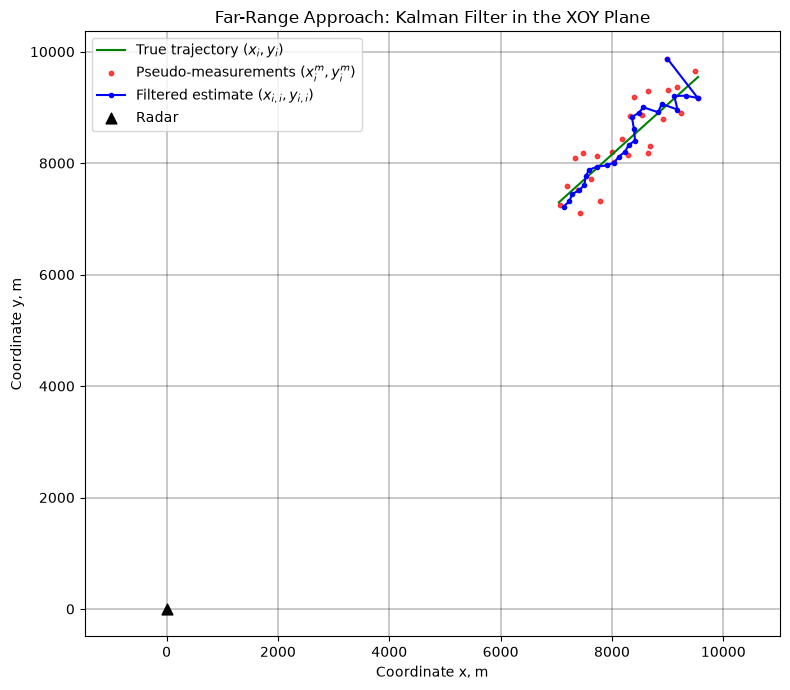

In [12]:
# a function to plot the true trajectory, the pseudo-measurements and the filtered estimate in the XOY plane
def plot_cartesian(x, y, z, x_filt, title):
    fig, ax = plt.subplots(figsize=(8, 7))
    ax.plot(x, y, color="green", linewidth=1.5, label="True trajectory $(x_i, y_i)$")
    ax.scatter(z[:, 0, 0], z[:, 1, 0], color="red", s=10, alpha=0.7, label="Pseudo-measurements $(x^m_i, y^m_i)$")
    ax.plot(x_filt[1:, 0, 0], x_filt[1:, 2, 0], color="blue", linewidth=1.5, marker=".",
            label="Filtered estimate $(x_{i,i}, y_{i,i})$")
    ax.scatter([0], [0], color="black", marker="^", s=60, label="Radar")
    ax.set_title(title)
    ax.set_xlabel("Coordinate x, m")
    ax.set_ylabel("Coordinate y, m")
    ax.set_aspect("equal", adjustable="datalim")
    ax.grid(True, color="black", linewidth=0.3)
    ax.legend(frameon=True)
    fig.tight_layout()
    plt.show()

x_pred_far, P_pred_far, x_filt_far, P_filt_far, K_far = kalman_filter(z_far, R_far, PHI, H, X_0_0, P_0_0)
plot_cartesian(x_far, y_far, z_far, x_filt_far, "Far-Range Approach: Kalman Filter in the XOY Plane")

d_pred_far, beta_pred_far = estimate_to_polar(x_pred_far)
d_filt_far, beta_filt_far = estimate_to_polar(x_filt_far)

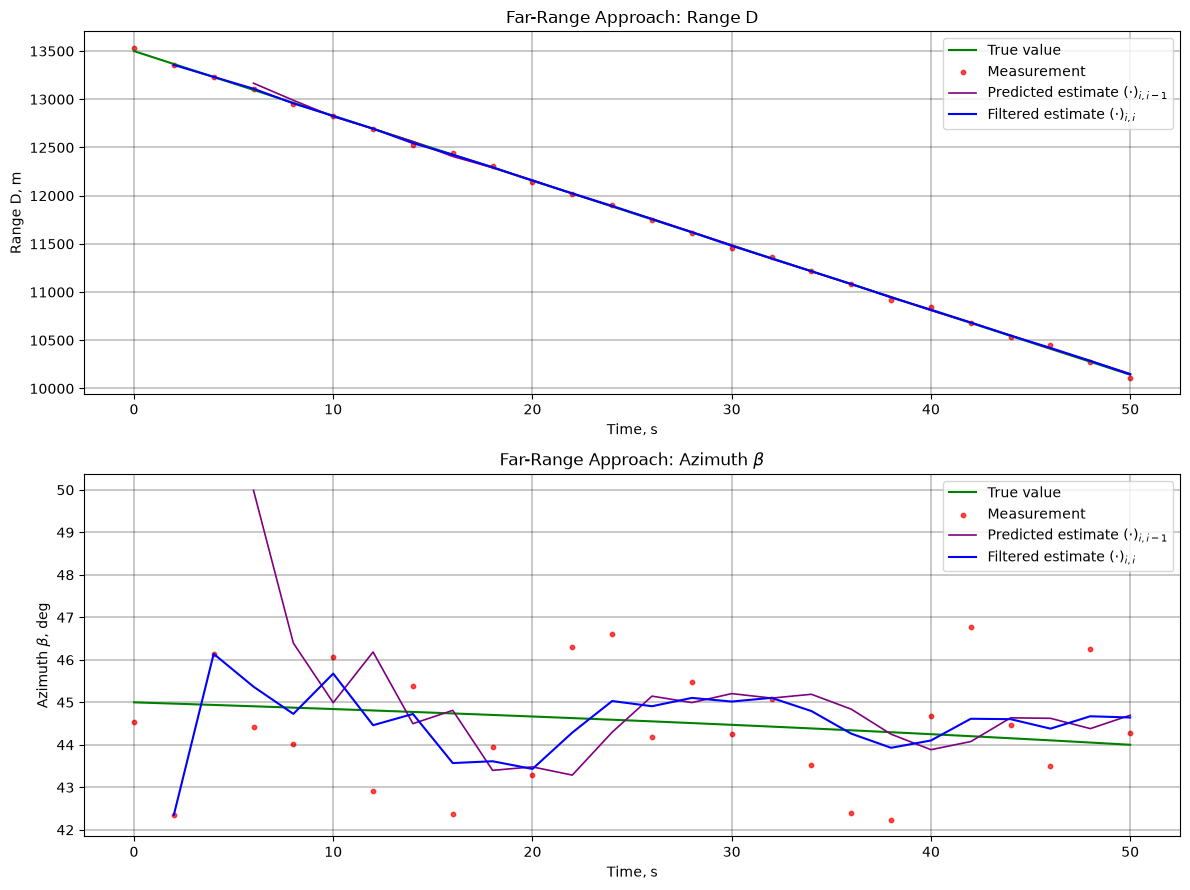

In [13]:
# a function to plot the true values, the measurements, the predicted and filtered estimates of range and azimuth
def plot_polar_estimates(d, beta, d_m, beta_m, d_pred, beta_pred, d_filt, beta_filt, title, start=START):
    fig, axes = plt.subplots(2, 1, figsize=(12, 9))
    for ax, true, meas, pred, filt, name, unit in [
            (axes[0], d, d_m, d_pred, d_filt, "Range D", "m"),
            (axes[1], np.degrees(beta), np.degrees(beta_m), np.degrees(beta_pred), np.degrees(beta_filt), "Azimuth $\\beta$", "deg")]:
        ax.plot(steps, true, color="green", linewidth=1.5, label="True value")
        ax.scatter(steps, meas, color="red", s=10, alpha=0.7, label="Measurement")
        ax.plot(steps[start:], pred[start:], color="purple", linewidth=1.2, label="Predicted estimate $(\\cdot)_{i,i-1}$")
        ax.plot(steps[1:], filt[1:], color="blue", linewidth=1.5, label="Filtered estimate $(\\cdot)_{i,i}$")
        ax.set_title(f"{title}: {name}")
        ax.set_xlabel("Time, s")
        ax.set_ylabel(f"{name}, {unit}")
        ax.grid(True, color="black", linewidth=0.3)
        ax.legend(frameon=True)
    fig.tight_layout()
    plt.show()

plot_polar_estimates(d_far, beta_far, d_m_far, beta_m_far, d_pred_far, beta_pred_far, d_filt_far, beta_filt_far,
                     "Far-Range Approach")

## Part II. Mission Check: Stress-Testing the Filter
### 1. True estimation errors of range and azimuth over $M = 500$ runs
$$\mathrm{Error}(\hat D_i) = \frac{1}{\sigma_D}\sqrt{\frac{1}{M-1}\sum_{j=1}^{M}\left(D_i - \hat D^{(j)}_i\right)^2}, \qquad
\mathrm{Error}(\hat \beta_i) = \frac{1}{\sigma_\beta}\sqrt{\frac{1}{M-1}\sum_{j=1}^{M}\left(\beta_i - \hat \beta^{(j)}_i\right)^2}$$
The true trajectory is deterministic, so only the measurements are generated anew in every run.

In [14]:
# true errors of the predicted and filtered estimates of range and azimuth over M runs, relative to sigma
def run_experiment(d, beta, sigma_d, sigma_beta, m_runs=M_RUNS):
    sq_err = {key: np.zeros((m_runs, POINTS)) for key in ("d_pred", "d_filt", "beta_pred", "beta_filt")}

    for run in range(m_runs):
        # new measurements in every run
        d_m, beta_m = generate_measurements(d, beta, sigma_d, sigma_beta)
        z = pseudo_measurements(d_m, beta_m)
        r = measurement_covariance(d_m, beta_m, sigma_d, sigma_beta)
        x_pred, _, x_filt, _, _ = kalman_filter(z, r, PHI, H, X_0_0, P_0_0)

        d_pred, beta_pred = estimate_to_polar(x_pred)
        d_filt, beta_filt = estimate_to_polar(x_filt)
        sq_err["d_pred"][run] = (d - d_pred)**2
        sq_err["d_filt"][run] = (d - d_filt)**2
        sq_err["beta_pred"][run] = (beta - beta_pred)**2
        sq_err["beta_filt"][run] = (beta - beta_filt)**2

    # root of the sum over runs divided by (M - 1), as in assignment 6, and divided by sigma of the measurement noise
    sigma = {"d_pred": sigma_d, "d_filt": sigma_d, "beta_pred": sigma_beta, "beta_filt": sigma_beta}
    return {key: np.sqrt(np.sum(sq, axis=0) / (m_runs - 1)) / sigma[key] for key, sq in sq_err.items()}

# a function to plot the relative errors of the predicted and filtered estimates of range and azimuth
def plot_relative_errors(errors, title, start=START):
    fig, axes = plt.subplots(2, 1, figsize=(12, 9))
    for ax, name, key, sigma in [(axes[0], "Range D", "d", "$\\sigma_D$"),
                                 (axes[1], "Azimuth $\\beta$", "beta", "$\\sigma_\\beta$")]:
        ax.plot(steps[start:], errors[f"{key}_pred"][start:], color="purple", linewidth=1.5,
                label=f"Predicted estimate ({M_RUNS} runs)")
        ax.plot(steps[start:], errors[f"{key}_filt"][start:], color="blue", linewidth=1.5,
                label=f"Filtered estimate ({M_RUNS} runs)")
        ax.axhline(1, color="red", linestyle="--", linewidth=1, label=f"Measurement error {sigma}")
        ax.set_title(f"{title}: True Errors of {name} Relative to {sigma}")
        ax.set_xlabel("Time, s")
        ax.set_ylabel(f"Error / {sigma}")
        ax.grid(True, color="black", linewidth=0.3)
        ax.legend(frameon=True)
    fig.tight_layout()
    plt.show()

# relative errors at selected steps
def print_errors(errors, check_steps=(START, 10, 15, 20, POINTS - 1)):
    print(f"{'step':<6}{'t, s':<6}" + "".join(f"{key:>12}" for key in errors))
    for i in check_steps:
        print(f"{i:<6}{steps[i]:<6}" + "".join(f"{errors[key][i]:>12.2f}" for key in errors))

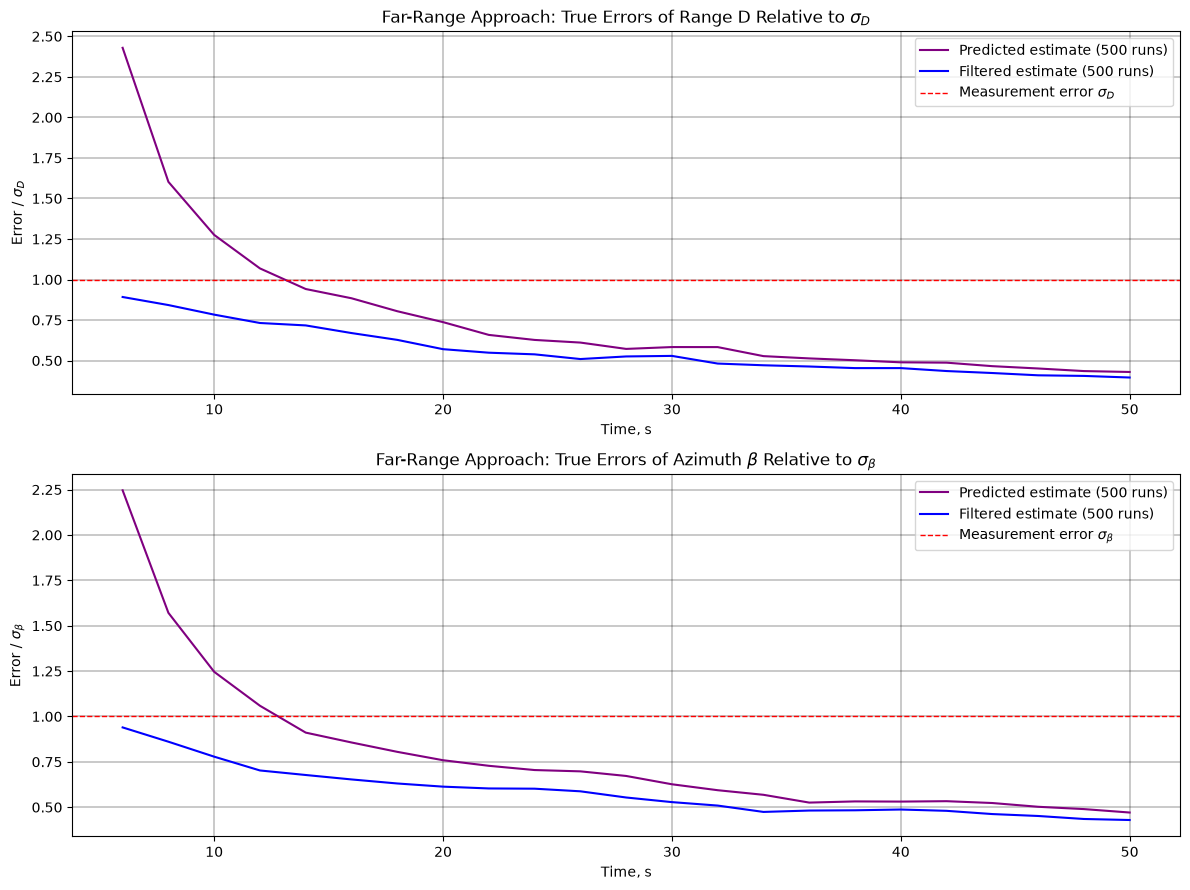

step  t, s        d_pred      d_filt   beta_pred   beta_filt
3     6             2.43        0.89        2.25        0.94
10    20            0.74        0.57        0.76        0.61
15    30            0.58        0.53        0.63        0.53
20    40            0.49        0.45        0.53        0.49
25    50            0.43        0.40        0.47        0.43


In [15]:
errors_far = run_experiment(d_far, beta_far, SIGMA_D, SIGMA_BETA)
plot_relative_errors(errors_far, "Far-Range Approach")
print_errors(errors_far)

### 2. Dependence of the true coordinate $x$ on the true azimuth $\beta$
$$x = D\sin\beta$$
To measure how far the curve is from a straight line, the maximum deviation of $x(\beta)$ from the chord through its end points is calculated. The local linearization error of the pseudo-measurement is the second-order term of the Taylor series, $\approx \frac{1}{2}D\sigma_\beta^2$.

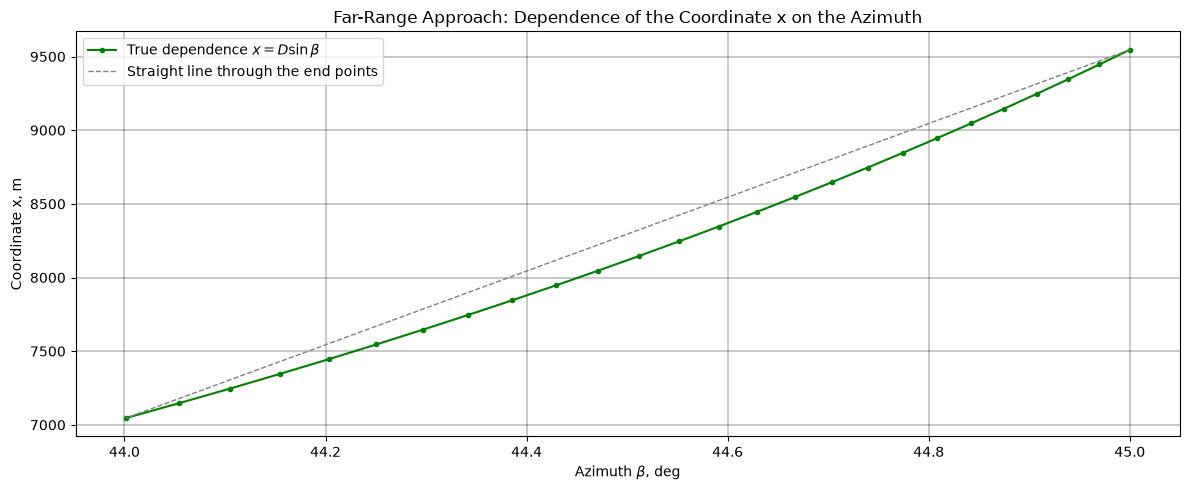

beta changes by 1.00 deg, x changes by 2500 m
maximum deviation from the straight line: 178.2 m (7.1% of the change of x)
second-order linearization term D * sigma_beta^2 / 2: 2.029 - 2.700 m


In [16]:
# a function to plot the true coordinate x against the true azimuth beta, together with the chord through the end points
def plot_x_vs_beta(x, beta, d, sigma_beta, title):
    chord = x[0] + (x[-1] - x[0]) * (beta - beta[0]) / (beta[-1] - beta[0])
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(np.degrees(beta), x, color="green", linewidth=1.5, marker=".", label="True dependence $x = D\\sin\\beta$")
    ax.plot(np.degrees(beta), chord, color="gray", linestyle="--", linewidth=1, label="Straight line through the end points")
    ax.set_title(title)
    ax.set_xlabel("Azimuth $\\beta$, deg")
    ax.set_ylabel("Coordinate x, m")
    ax.grid(True, color="black", linewidth=0.3)
    ax.legend(frameon=True)
    fig.tight_layout()
    plt.show()

    print(f"beta changes by {np.degrees(np.abs(beta[-1] - beta[0])):.2f} deg, x changes by {np.abs(x[-1] - x[0]):.0f} m")
    print(f"maximum deviation from the straight line: {np.max(np.abs(x - chord)):.1f} m "
          f"({100 * np.max(np.abs(x - chord)) / np.abs(x[-1] - x[0]):.1f}% of the change of x)")
    print(f"second-order linearization term D * sigma_beta^2 / 2: {np.min(d) * sigma_beta**2 / 2:.3f} - "
          f"{np.max(d) * sigma_beta**2 / 2:.3f} m")

plot_x_vs_beta(x_far, beta_far, d_far, SIGMA_BETA, "Far-Range Approach: Dependence of the Coordinate x on the Azimuth")

### 3. Condition number of the covariance matrix $R$
$$\mathrm{cond}(R_i) = \frac{\lambda_{\max}(R_i)}{\lambda_{\min}(R_i)}$$
The eigenvalues of $R_i$ are $\sigma_D^2$ (along the line of sight) and $(D^m_i)^2\sigma_\beta^2$ (across it), so
$\mathrm{cond}(R_i) = \max\left(\frac{\sigma_D^2}{D_i^2\sigma_\beta^2}, \frac{D_i^2\sigma_\beta^2}{\sigma_D^2}\right)$.

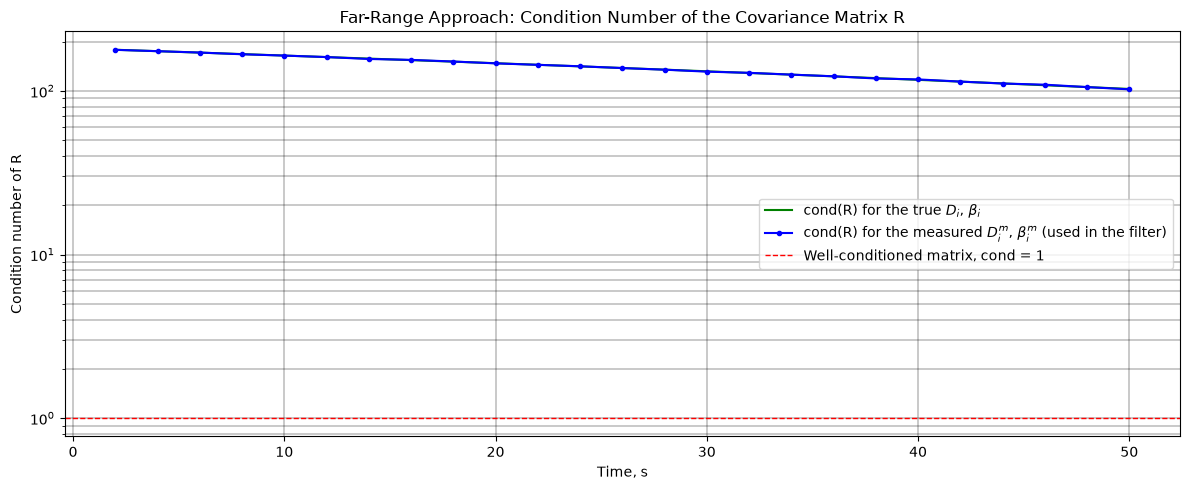

cond(R): 178.4 -> 102.3


In [17]:
# condition numbers of R_i calculated from the measurements and from the true values of range and azimuth
def condition_numbers(r):
    return np.linalg.cond(r)

def plot_condition_numbers(cond_meas, cond_true, title, start=1):
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(steps[start:], cond_true[start:], color="green", linewidth=1.5, label="cond(R) for the true $D_i$, $\\beta_i$")
    ax.plot(steps[start:], cond_meas[start:], color="blue", linewidth=1.5, marker=".",
            label="cond(R) for the measured $D^m_i$, $\\beta^m_i$ (used in the filter)")
    ax.axhline(1, color="red", linestyle="--", linewidth=1, label="Well-conditioned matrix, cond = 1")
    ax.set_yscale("log")
    ax.set_title(title)
    ax.set_xlabel("Time, s")
    ax.set_ylabel("Condition number of R")
    ax.grid(True, which="both", color="black", linewidth=0.3)
    ax.legend(frameon=True)
    fig.tight_layout()
    plt.show()

cond_far = condition_numbers(R_far)
cond_true_far = condition_numbers(measurement_covariance(d_far, beta_far, SIGMA_D, SIGMA_BETA))
plot_condition_numbers(cond_far, cond_true_far, "Far-Range Approach: Condition Number of the Covariance Matrix R")
print(f"cond(R): {cond_far[1]:.1f} -> {cond_far[-1]:.1f}")

### 4. Filter gain $K(1,1)$

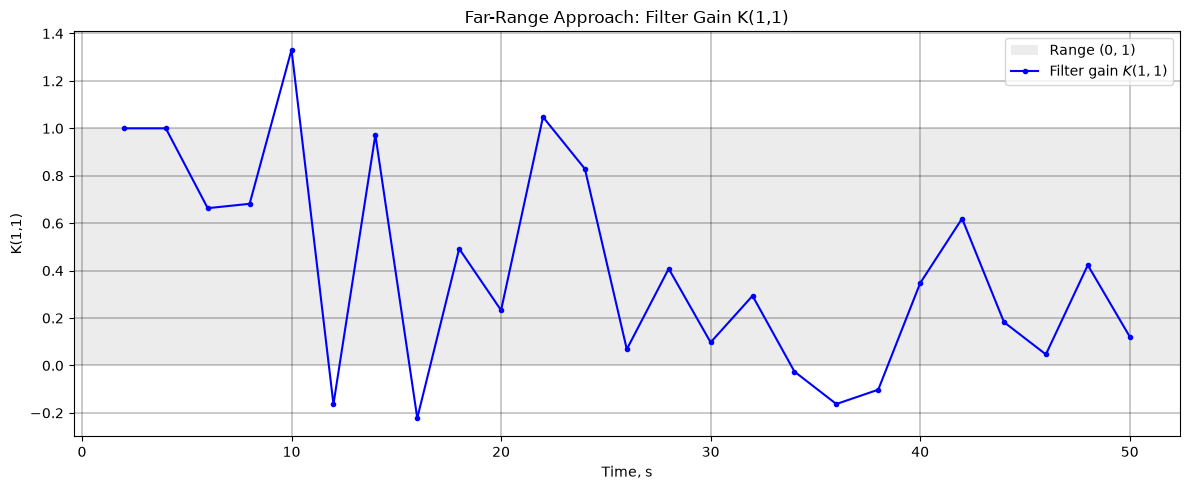

K(1,1): min = -0.22, max = 1.33, outside (0, 1) at 7 steps


In [18]:
# a function to plot the element K(1,1) of the filter gain of one realization
def plot_gain(k, title, start=1):
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.axhspan(0, 1, color="gray", alpha=0.15, linewidth=0, label="Range (0, 1)")
    ax.plot(steps[start:], k[start:, 0, 0], color="blue", linewidth=1.5, marker=".", label="Filter gain $K(1,1)$")
    ax.set_title(title)
    ax.set_xlabel("Time, s")
    ax.set_ylabel("K(1,1)")
    ax.grid(True, color="black", linewidth=0.3)
    ax.legend(frameon=True)
    fig.tight_layout()
    plt.show()

plot_gain(K_far, "Far-Range Approach: Filter Gain K(1,1)")
outside = np.sum((K_far[1:, 0, 0] < 0) | (K_far[1:, 0, 0] > 1))
print(f"K(1,1): min = {np.min(K_far[1:, 0, 0]):.2f}, max = {np.max(K_far[1:, 0, 0]):.2f}, outside (0, 1) at {outside} steps")

### 5. Close fly-by: $x_0 = y_0 = 3500/\sqrt{2}$ m

D: 3500.0 -> 226.3 m, beta: 45.00 -> -6.38 deg


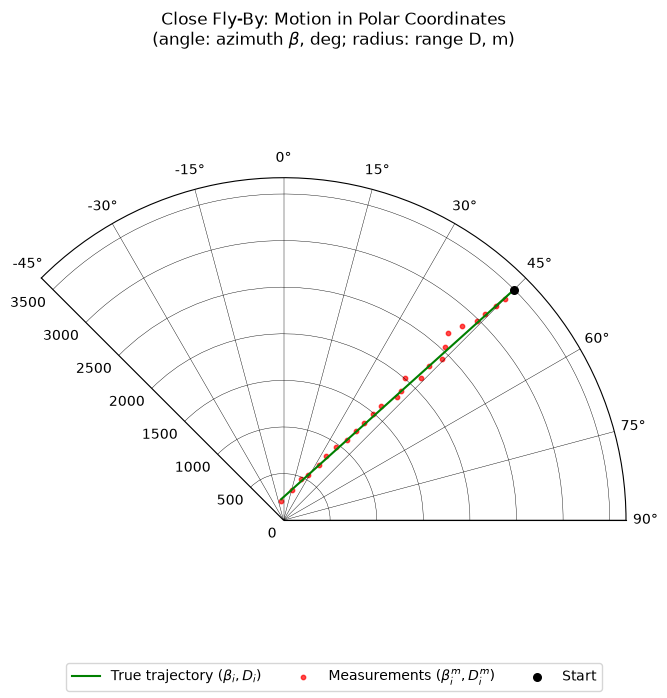

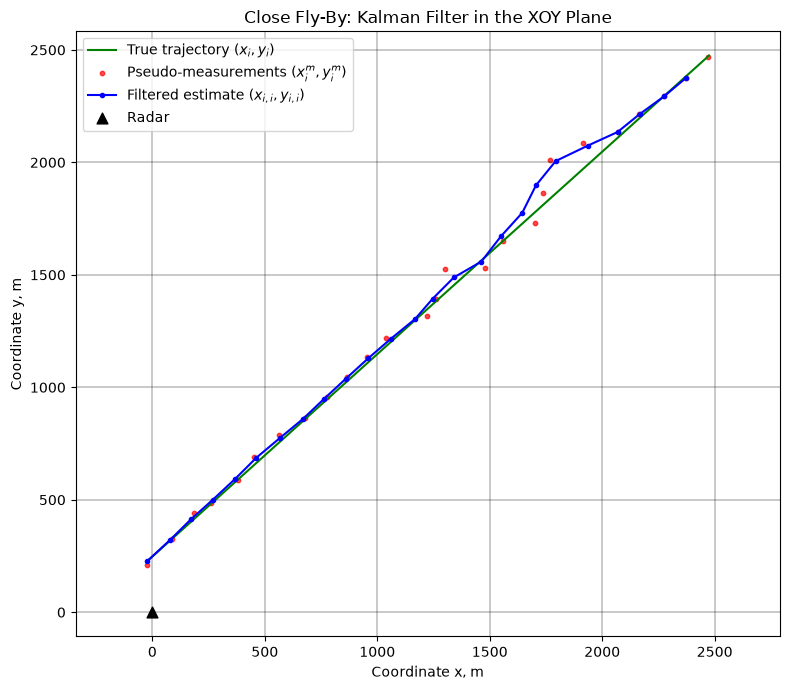

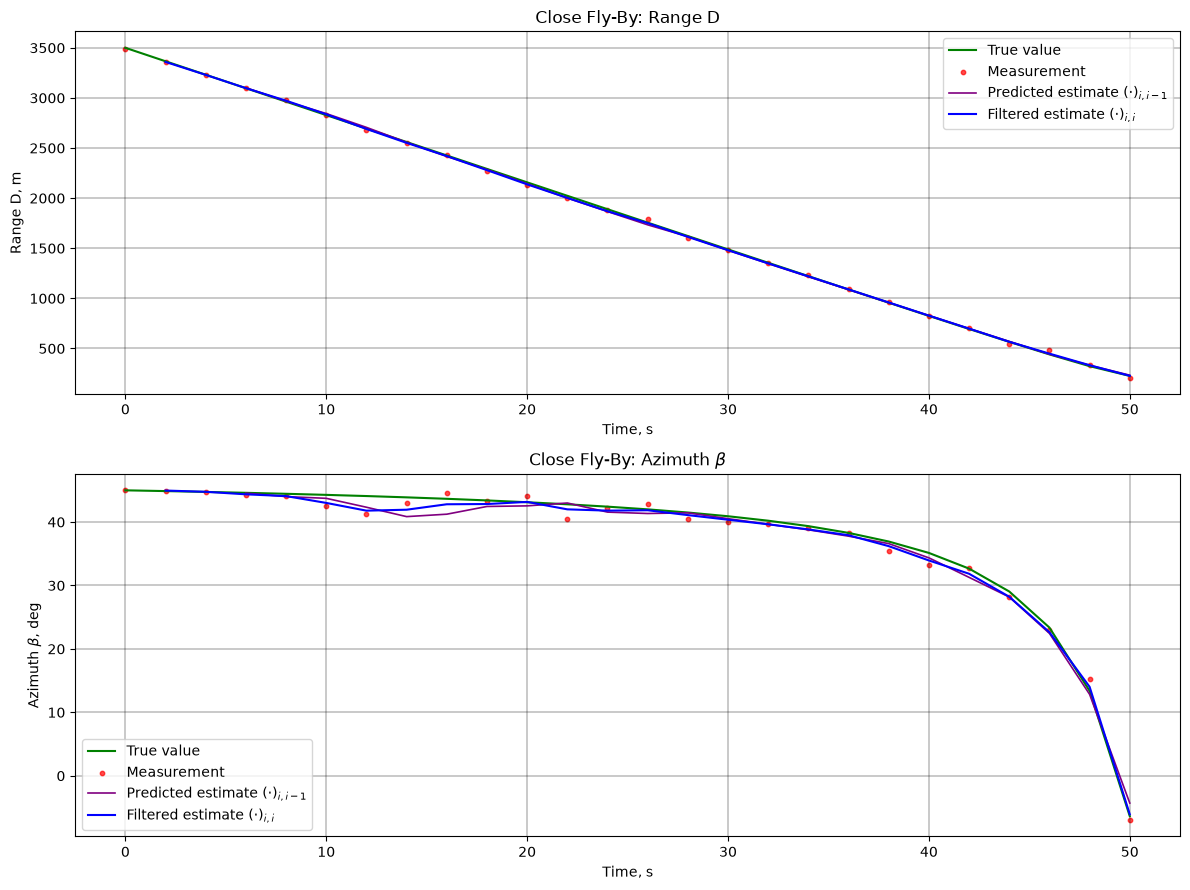

In [19]:
# a function to run all steps of Part I for one scenario: measurements, pseudo-measurements, R_i and the filter
def run_single(x, y, d, beta, sigma_d, sigma_beta):
    d_m, beta_m = generate_measurements(d, beta, sigma_d, sigma_beta)
    z = pseudo_measurements(d_m, beta_m)
    r = measurement_covariance(d_m, beta_m, sigma_d, sigma_beta)
    x_pred, p_pred, x_filt, p_filt, k = kalman_filter(z, r, PHI, H, X_0_0, P_0_0)
    return d_m, beta_m, z, r, x_pred, x_filt, k

x_close, vx_close, y_close, vy_close = generate_true_trajectory(X_INIT_CLOSE, Y_INIT_CLOSE)
d_close, beta_close = to_polar(x_close, y_close)
print(f"D: {d_close[0]:.1f} -> {d_close[-1]:.1f} m, beta: {np.degrees(beta_close[0]):.2f} -> {np.degrees(beta_close[-1]):.2f} deg")

d_m_close, beta_m_close, z_close, R_close, x_pred_close, x_filt_close, K_close = run_single(
    x_close, y_close, d_close, beta_close, SIGMA_D, SIGMA_BETA)
plot_polar(d_close, beta_close, d_m_close, beta_m_close, "Close Fly-By: Motion in Polar Coordinates")
plot_cartesian(x_close, y_close, z_close, x_filt_close, "Close Fly-By: Kalman Filter in the XOY Plane")

d_pred_close, beta_pred_close = estimate_to_polar(x_pred_close)
d_filt_close, beta_filt_close = estimate_to_polar(x_filt_close)
plot_polar_estimates(d_close, beta_close, d_m_close, beta_m_close, d_pred_close, beta_pred_close,
                     d_filt_close, beta_filt_close, "Close Fly-By")

In [ ]:
plot_true_trajectory(x_close, y_close, d_close, beta_close, "True Trajectory — Close Fly-By")

### 6. True estimation errors, close fly-by

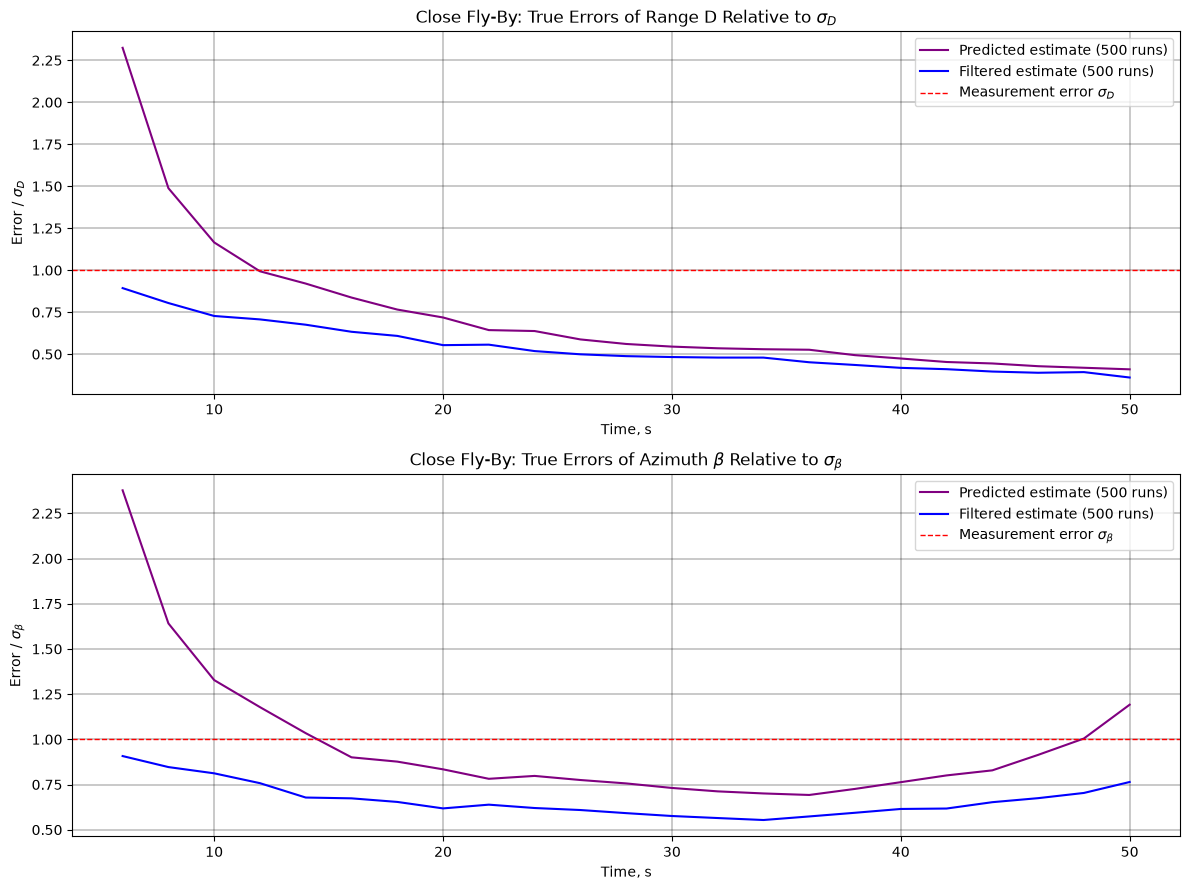

step  t, s        d_pred      d_filt   beta_pred   beta_filt
3     6             2.32        0.89        2.38        0.91
10    20            0.72        0.55        0.83        0.62
15    30            0.55        0.48        0.73        0.58
20    40            0.47        0.42        0.76        0.61
25    50            0.41        0.36        1.19        0.76


In [20]:
errors_close = run_experiment(d_close, beta_close, SIGMA_D, SIGMA_BETA)
plot_relative_errors(errors_close, "Close Fly-By")
print_errors(errors_close)

### 7. Dependence of $x$ on $\beta$, close fly-by

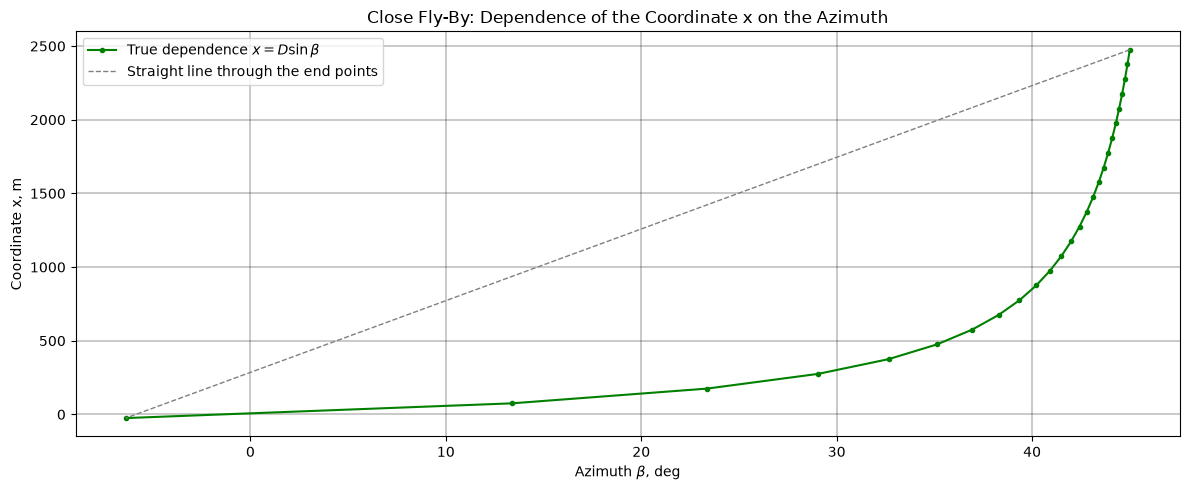

beta changes by 51.38 deg, x changes by 2500 m
maximum deviation from the straight line: 1519.8 m (60.8% of the change of x)
second-order linearization term D * sigma_beta^2 / 2: 0.045 - 0.700 m


In [21]:
plot_x_vs_beta(x_close, beta_close, d_close, SIGMA_BETA, "Close Fly-By: Dependence of the Coordinate x on the Azimuth")

### 8. Condition number of $R$, close fly-by

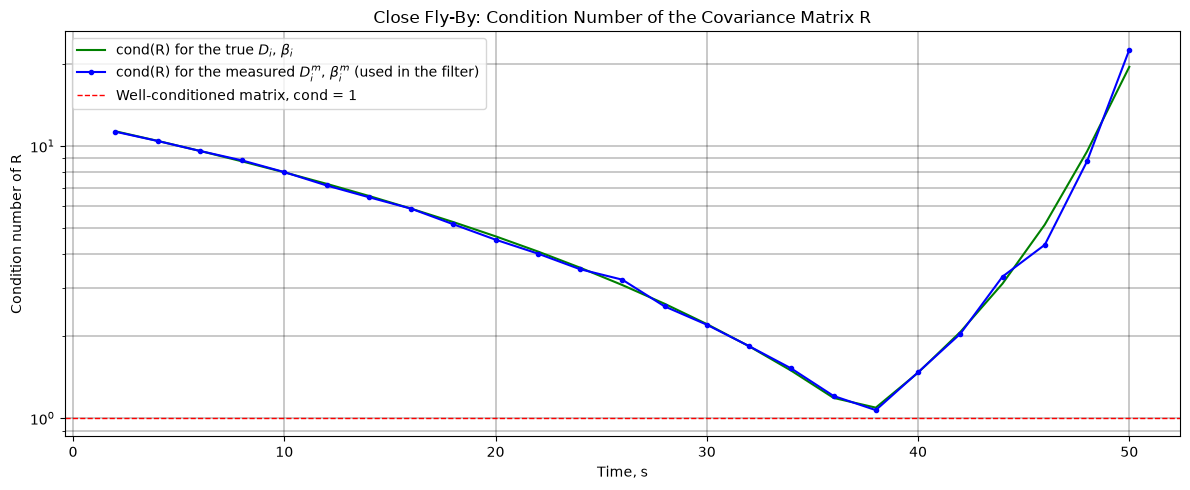

cond(R): 11.3 -> min 1.07 at t = 38 s (D = 957 m) -> 22.6
D * sigma_beta = sigma_D at D = 1000 m


In [22]:
cond_close = condition_numbers(R_close)
cond_true_close = condition_numbers(measurement_covariance(d_close, beta_close, SIGMA_D, SIGMA_BETA))
plot_condition_numbers(cond_close, cond_true_close, "Close Fly-By: Condition Number of the Covariance Matrix R")
i_min = np.argmin(cond_true_close)
print(f"cond(R): {cond_close[1]:.1f} -> min {cond_close[i_min]:.2f} at t = {steps[i_min]} s (D = {d_close[i_min]:.0f} m) -> {cond_close[-1]:.1f}")
print(f"D * sigma_beta = sigma_D at D = {SIGMA_D / SIGMA_BETA:.0f} m")

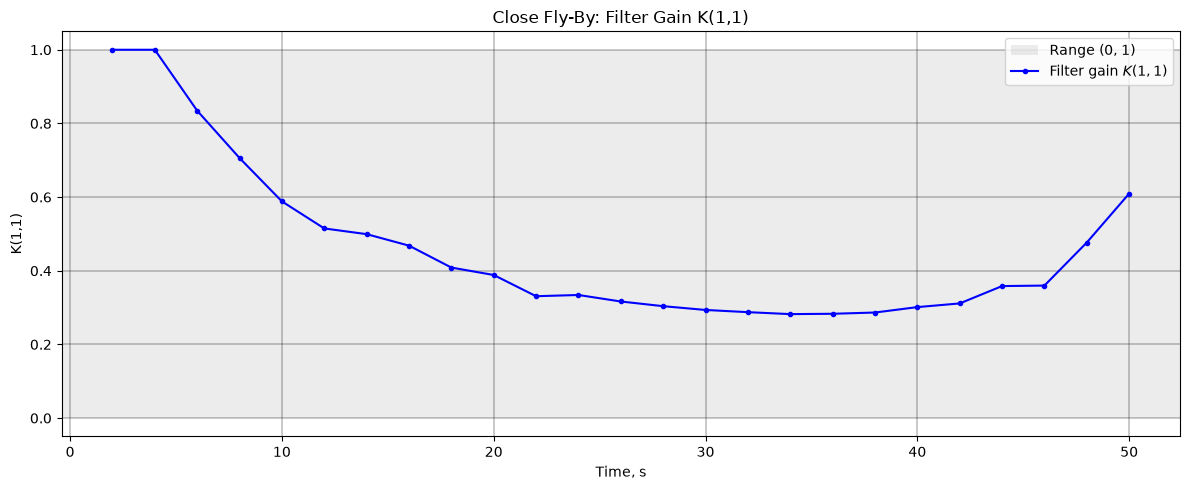

K(1,1): min = 0.28, max = 1.00, outside (0, 1) at 0 steps


In [23]:
plot_gain(K_close, "Close Fly-By: Filter Gain K(1,1)")
outside = np.sum((K_close[1:, 0, 0] < 0) | (K_close[1:, 0, 0] > 1))
print(f"K(1,1): min = {np.min(K_close[1:, 0, 0]):.2f}, max = {np.max(K_close[1:, 0, 0]):.2f}, outside (0, 1) at {outside} steps")

### 10–11. Close fly-by with accurate azimuth: $\sigma_D = 50$ m, $\sigma_\beta = 0.0015$ rad

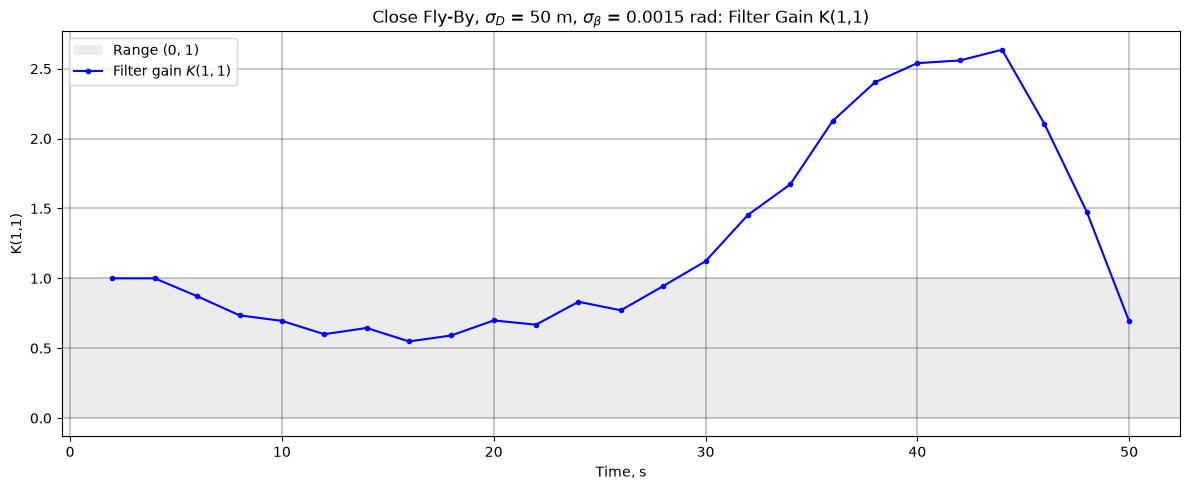

K(1,1): min = 0.55, max = 2.64, outside (0, 1) at 10 steps


In [24]:
d_m_pb, beta_m_pb, z_pb, R_pb, x_pred_pb, x_filt_pb, K_pb = run_single(
    x_close, y_close, d_close, beta_close, SIGMA_D_PRECISE_BETA, SIGMA_BETA_PRECISE_BETA)

plot_gain(K_pb, "Close Fly-By, $\\sigma_D$ = 50 m, $\\sigma_\\beta$ = 0.0015 rad: Filter Gain K(1,1)")
outside = np.sum((K_pb[1:, 0, 0] < 0) | (K_pb[1:, 0, 0] > 1))
print(f"K(1,1): min = {np.min(K_pb[1:, 0, 0]):.2f}, max = {np.max(K_pb[1:, 0, 0]):.2f}, outside (0, 1) at {outside} steps")

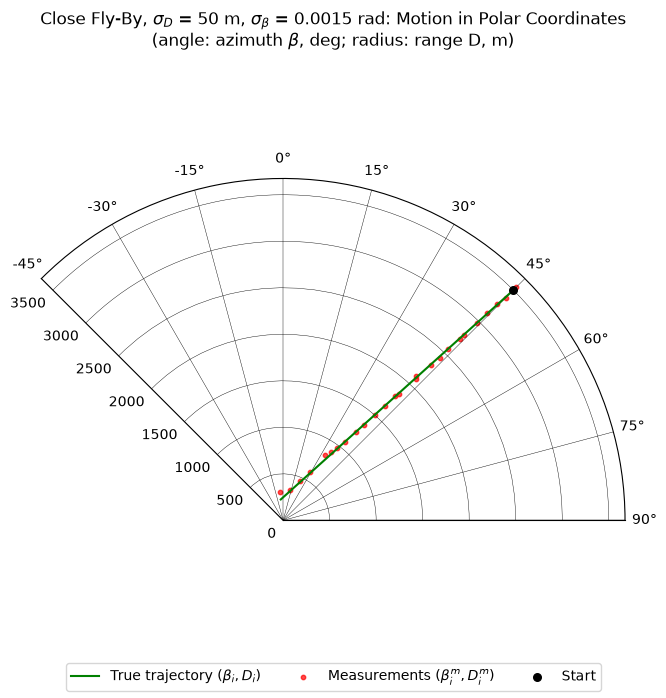

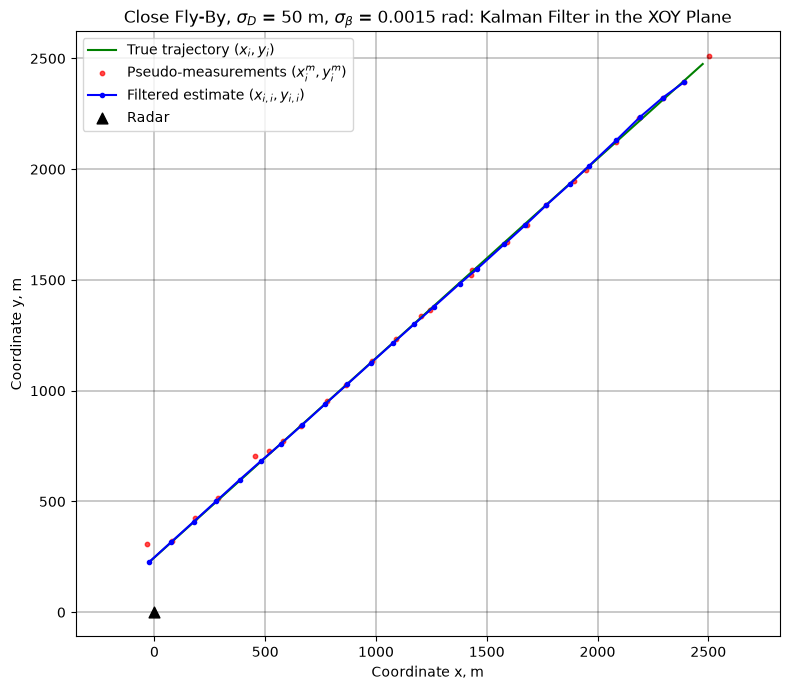

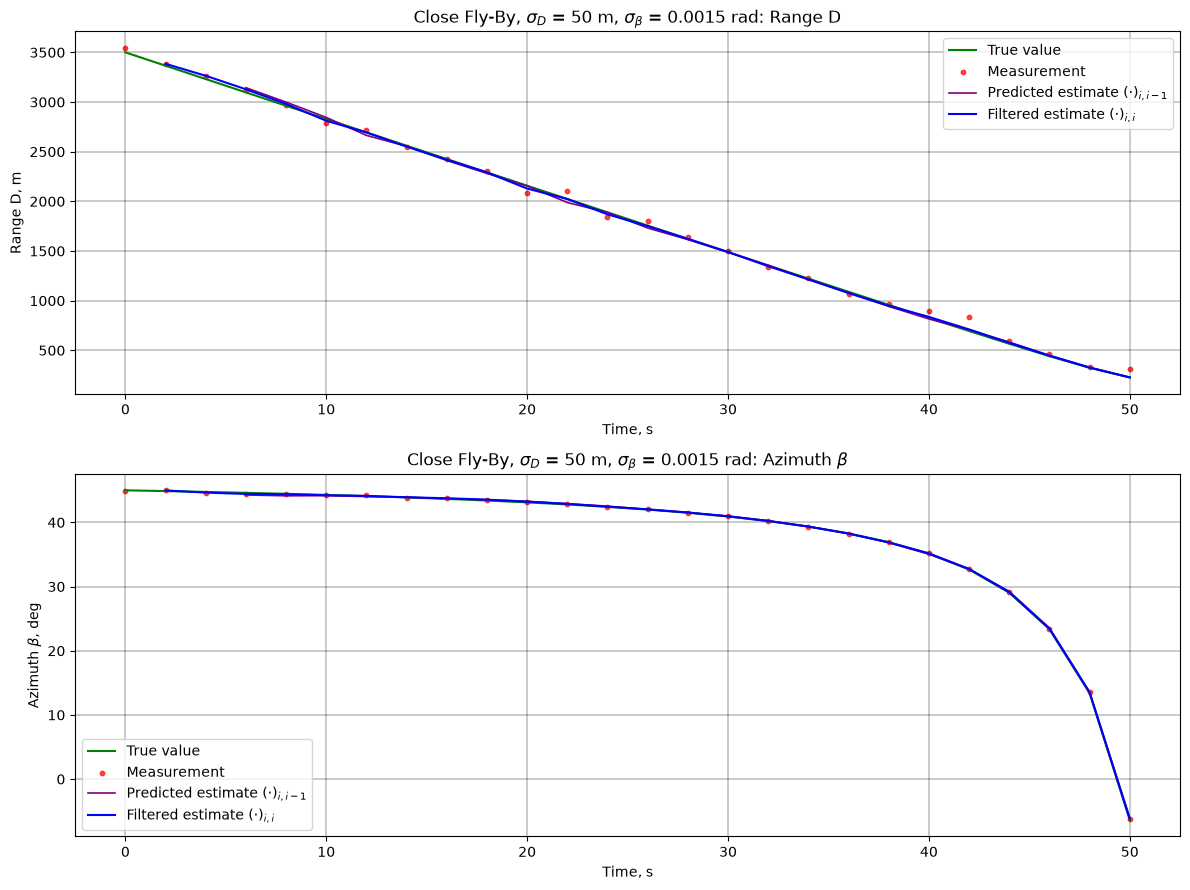

In [25]:
plot_polar(d_close, beta_close, d_m_pb, beta_m_pb,
           "Close Fly-By, $\\sigma_D$ = 50 m, $\\sigma_\\beta$ = 0.0015 rad: Motion in Polar Coordinates")
plot_cartesian(x_close, y_close, z_pb, x_filt_pb,
               "Close Fly-By, $\\sigma_D$ = 50 m, $\\sigma_\\beta$ = 0.0015 rad: Kalman Filter in the XOY Plane")

d_pred_pb, beta_pred_pb = estimate_to_polar(x_pred_pb)
d_filt_pb, beta_filt_pb = estimate_to_polar(x_filt_pb)
plot_polar_estimates(d_close, beta_close, d_m_pb, beta_m_pb, d_pred_pb, beta_pred_pb, d_filt_pb, beta_filt_pb,
                     "Close Fly-By, $\\sigma_D$ = 50 m, $\\sigma_\\beta$ = 0.0015 rad")

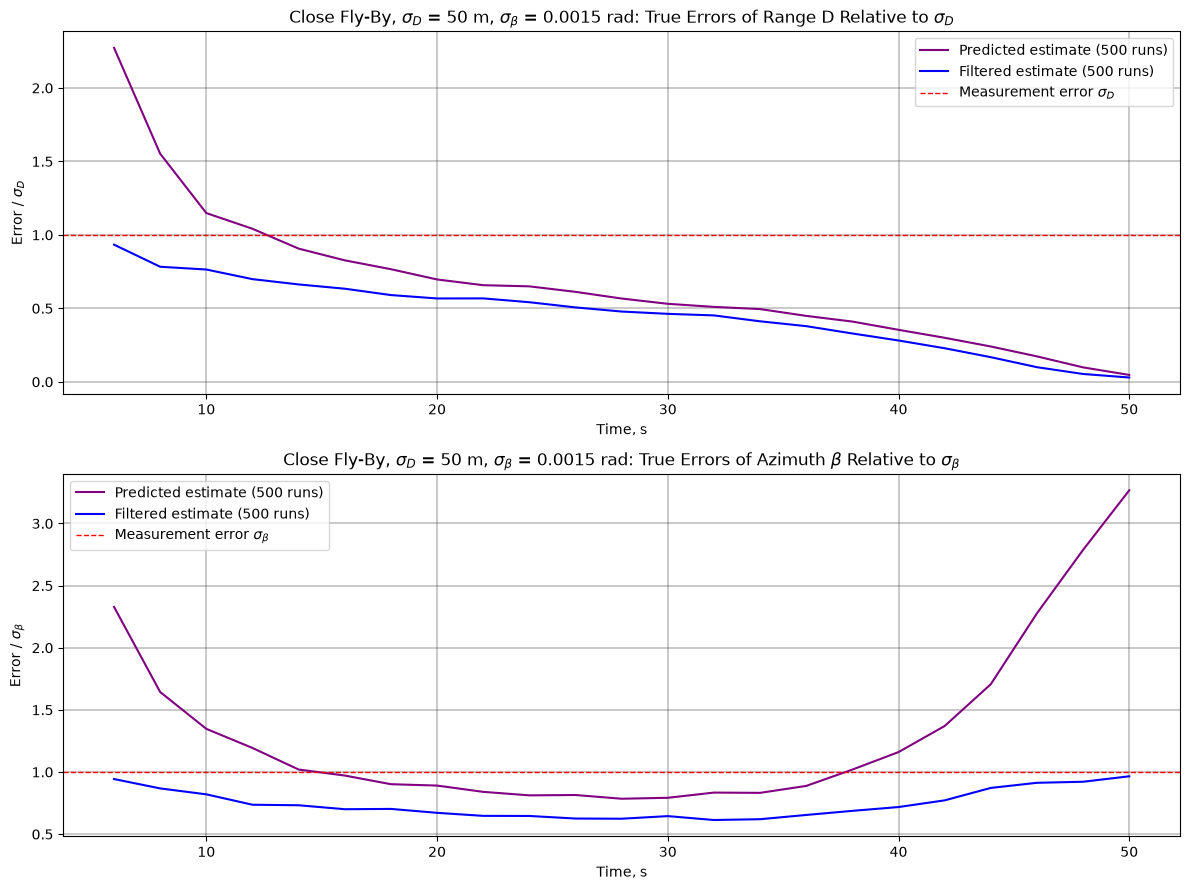

step  t, s        d_pred      d_filt   beta_pred   beta_filt
3     6             2.27        0.93        2.33        0.94
10    20            0.70        0.57        0.89        0.67
15    30            0.53        0.46        0.79        0.65
20    40            0.35        0.28        1.16        0.72
25    50            0.05        0.03        3.27        0.97


In [26]:
errors_pb = run_experiment(d_close, beta_close, SIGMA_D_PRECISE_BETA, SIGMA_BETA_PRECISE_BETA)
plot_relative_errors(errors_pb, "Close Fly-By, $\\sigma_D$ = 50 m, $\\sigma_\\beta$ = 0.0015 rad")
print_errors(errors_pb)

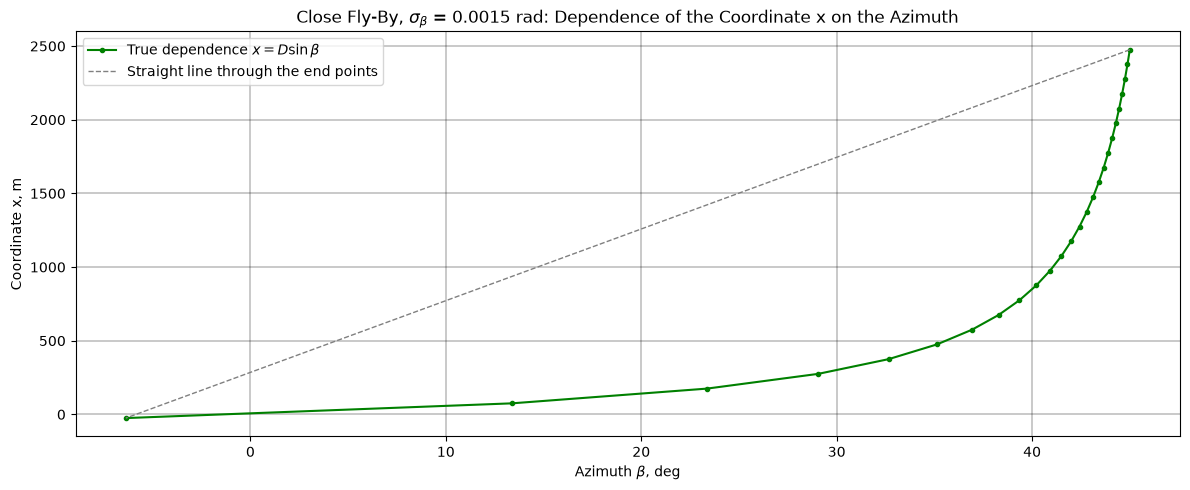

beta changes by 51.38 deg, x changes by 2500 m
maximum deviation from the straight line: 1519.8 m (60.8% of the change of x)
second-order linearization term D * sigma_beta^2 / 2: 0.000 - 0.004 m


In [27]:
plot_x_vs_beta(x_close, beta_close, d_close, SIGMA_BETA_PRECISE_BETA,
               "Close Fly-By, $\\sigma_\\beta$ = 0.0015 rad: Dependence of the Coordinate x on the Azimuth")

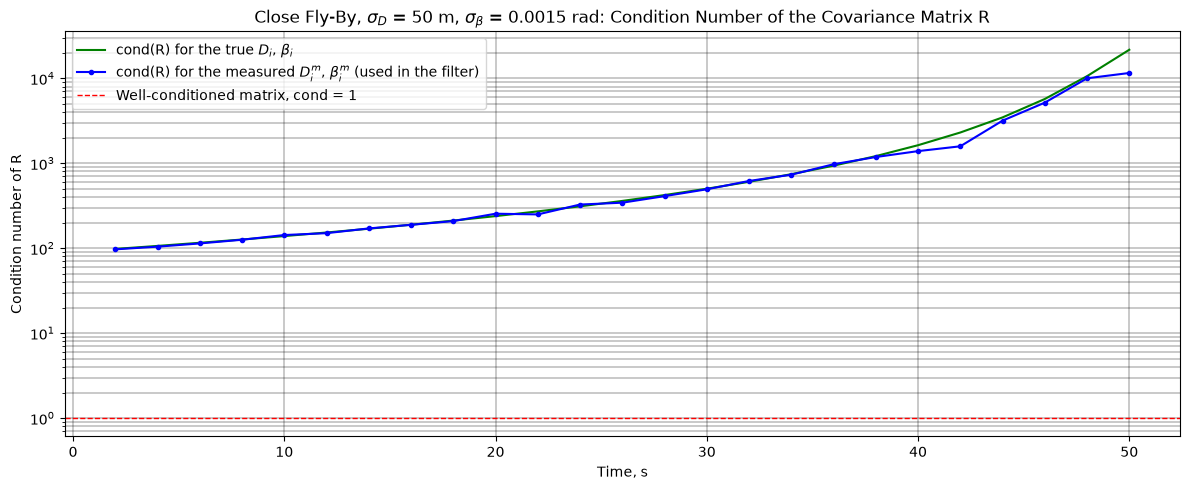

cond(R): 97.0 -> 11556.7, max = 11556.7


In [28]:
cond_pb = condition_numbers(R_pb)
cond_true_pb = condition_numbers(measurement_covariance(d_close, beta_close, SIGMA_D_PRECISE_BETA, SIGMA_BETA_PRECISE_BETA))
plot_condition_numbers(cond_pb, cond_true_pb,
                       "Close Fly-By, $\\sigma_D$ = 50 m, $\\sigma_\\beta$ = 0.0015 rad: Condition Number of the Covariance Matrix R")
print(f"cond(R): {cond_pb[1]:.1f} -> {cond_pb[-1]:.1f}, max = {np.max(cond_pb[1:]):.1f}")

### Comparison of the three scenarios

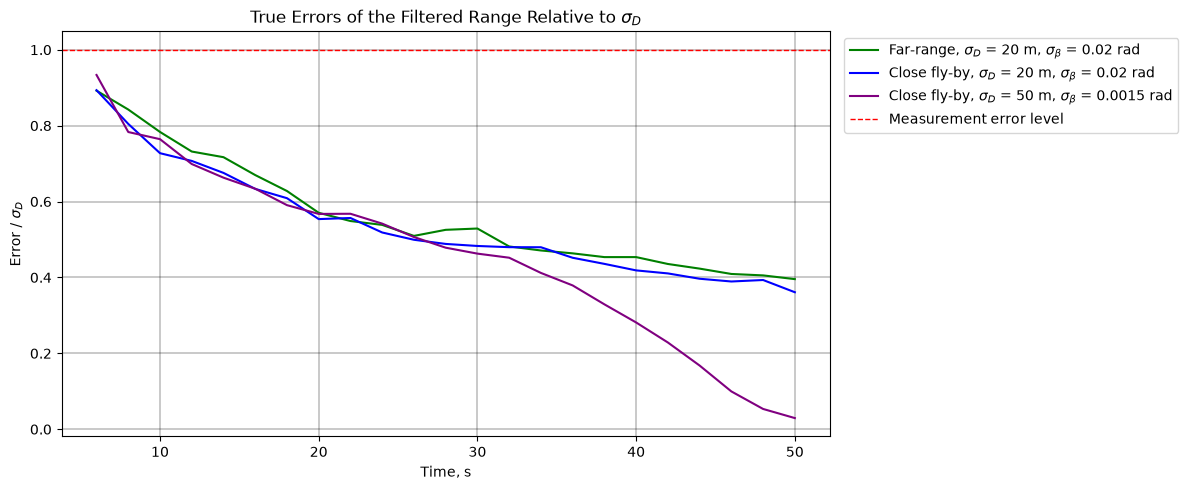

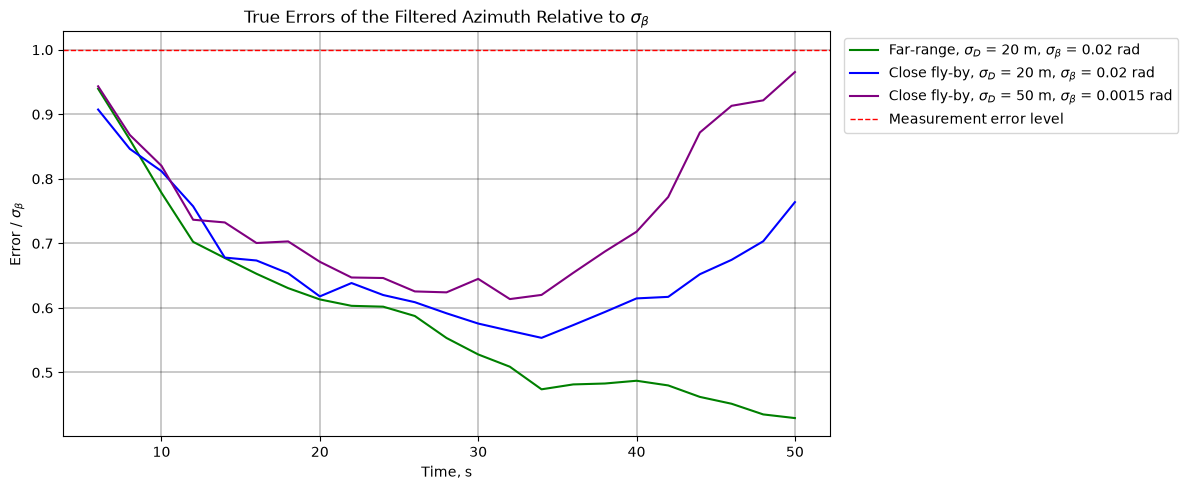

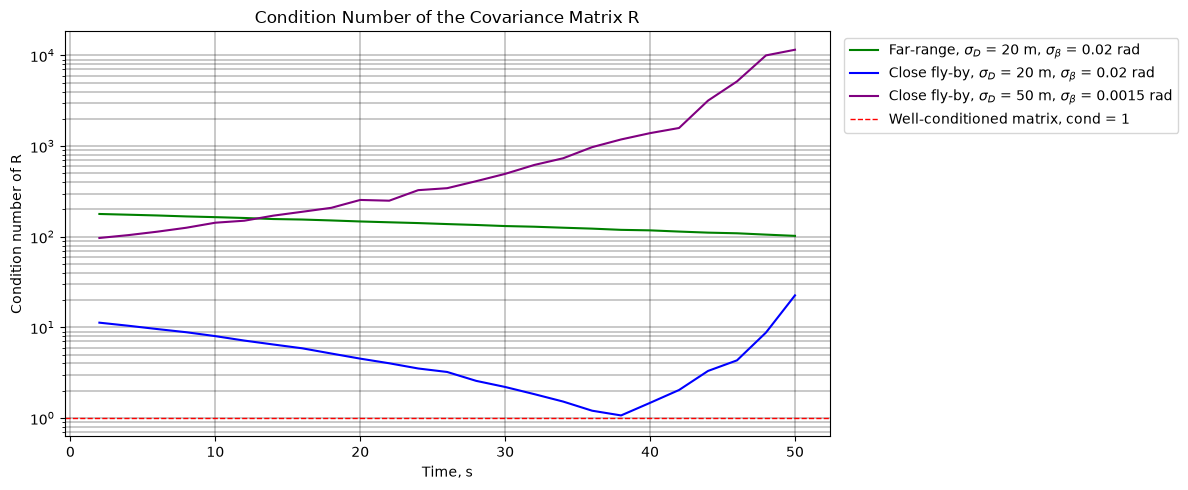

In [29]:
# a function to plot several curves on one figure (from assignment 8)
def plot_errors(curves, title, ylabel, start=START, level=1, level_label="Measurement error level", log=False):
    # curves: list of (values, label, color)
    fig, ax = plt.subplots(figsize=(12, 5))
    for values, label, color in curves:
        ax.plot(steps[start:], values[start:], color=color, linewidth=1.5, label=label)
    ax.axhline(level, color="red", linestyle="--", linewidth=1, label=level_label)
    if log:
        ax.set_yscale("log")
    ax.set_title(title)
    ax.set_xlabel("Time, s")
    ax.set_ylabel(ylabel)
    ax.grid(True, which="both", color="black", linewidth=0.3)
    ax.legend(frameon=True, loc="upper left", bbox_to_anchor=(1.01, 1))
    fig.tight_layout()
    plt.show()

scenarios = [(errors_far, "Far-range, $\\sigma_D$ = 20 m, $\\sigma_\\beta$ = 0.02 rad", "green"),
             (errors_close, "Close fly-by, $\\sigma_D$ = 20 m, $\\sigma_\\beta$ = 0.02 rad", "blue"),
             (errors_pb, "Close fly-by, $\\sigma_D$ = 50 m, $\\sigma_\\beta$ = 0.0015 rad", "purple")]
plot_errors([(err["d_filt"], label, color) for err, label, color in scenarios],
            "True Errors of the Filtered Range Relative to $\\sigma_D$", "Error / $\\sigma_D$")
plot_errors([(err["beta_filt"], label, color) for err, label, color in scenarios],
            "True Errors of the Filtered Azimuth Relative to $\\sigma_\\beta$", "Error / $\\sigma_\\beta$")
plot_errors([(cond, label, color) for cond, (_, label, color) in zip((cond_far, cond_close, cond_pb), scenarios)],
            "Condition Number of the Covariance Matrix R", "Condition number of R", start=1,
            level_label="Well-conditioned matrix, cond = 1", log=True)

In [30]:
# summary table: relative errors at the first shown step and at the last step
print(f"{'Scenario':<28}" + "".join(f"{key + ' ' + str(i):>16}" for key in errors_far for i in (START, POINTS - 1)))
for name, err in [("far, 20 m / 0.02 rad", errors_far), ("close, 20 m / 0.02 rad", errors_close),
                  ("close, 50 m / 0.0015 rad", errors_pb)]:
    print(f"{name:<28}" + "".join(f"{err[key][i]:>16.2f}" for key in err for i in (START, POINTS - 1)))

Scenario                            d_pred 3       d_pred 25        d_filt 3       d_filt 25     beta_pred 3    beta_pred 25     beta_filt 3    beta_filt 25
far, 20 m / 0.02 rad                    2.43            0.43            0.89            0.40            2.25            0.47            0.94            0.43
close, 20 m / 0.02 rad                  2.32            0.41            0.89            0.36            2.38            1.19            0.91            0.76
close, 50 m / 0.0015 rad                2.27            0.05            0.93            0.03            2.33            3.27            0.94            0.97
